## Preprocessing

Step 3 in the pipeline, where dataset is split into multiple different dataframes (detailed uses and reasons are given in `dataset_dictionary.md`).
Comments explain the code, detailed methodology is explained in the report.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import  RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import  accuracy_score


df = pd.read_csv("dataset.csv")

In [3]:
# Removing rows where HDI is NaN
df = df.drop(labels=df[df.Level.isna()].index) 

# Dropping country name (it does not serve as a predictor)
df = df.drop(columns=["Country"])
X = df.drop(columns =["Level"])
Y = df.Level

# Splitting data into test/train/validation (stratified split i.e roughly each class appears in the same amount in each split)
x_trv,x_te,y_trv,y_te = train_test_split(X,Y,random_state=10,stratify=Y,test_size=0.2)
x_tr,x_v,y_tr,y_v = train_test_split(x_trv,y_trv,random_state=10,stratify=y_trv,test_size=0.2)

print("Percentages of each class are-")
print(f"For train set\n{y_tr.value_counts()/len(y_tr)*100}\nFor validation set\n{y_v.value_counts()/len(y_v)*100}\
      \nFor test set\n{y_te.value_counts()/len(y_te)*100}")

Percentages of each class are-
For train set
Level
1.0    47.967480
2.0    38.211382
0.0    13.821138
Name: count, dtype: float64
For validation set
Level
1.0    48.387097
2.0    38.709677
0.0    12.903226
Name: count, dtype: float64      
For test set
Level
1.0    48.717949
2.0    38.461538
0.0    12.820513
Name: count, dtype: float64


The class count percentages (The class are 1,2,3 values of Level) are approximately the same across train,test and validation sets

Compared to Mean imputation Median imputation is more resistant to outliers, for example, if the highest value in a category becomes orders of magnitude higher than the rest, the mean increases greatly but theres no change to the median. As such we went with median imputation (our data has many outliers)\
But, it is possible that a value being missing is important information to predict the HDI, to account for this possibility, we are adding missing indicators, i.e for each numerical column, we are adding another column where each missing value gets a '1' and rest of the rows are '0'.


In [4]:
num_cols = x_tr.select_dtypes(include='number').columns
medians = [x_tr[col].median() for col in num_cols] # we found medians wrt train set

def impute_num(data):
    for col in num_cols:
        data[col+"missing"] = data[col].isna().astype(int) # adding missingness indicators
    data[num_cols] = data[num_cols].fillna(dict(zip(num_cols,medians)))
    
impute_num(x_tr)
impute_num(x_te)
impute_num(x_v)

In [5]:
cat_cols = x_tr.select_dtypes(exclude='number').columns
dummy_cols = pd.get_dummies(x_tr,columns = cat_cols).columns

def impute_col(data):
    data[cat_cols] = data[cat_cols].fillna("Missing")
    data = pd.get_dummies(data,columns = cat_cols)
    data = data.reindex(columns=dummy_cols,fill_value=0) #dealing with unseen categories
    return data

x_tr= impute_col(x_tr)
x_te=impute_col(x_te)
x_v=impute_col(x_v)

In [6]:
# Check if any NaNs remaining
x_tr.isna().sum()+ x_v.isna().sum()+ x_te.isna().sum()

Agriculture                              0
Industry                                 0
Services                                 0
Access_to_electricity                    0
Inflation_consumer_prices                0
Individuals_using_the_Internet           0
Trade                                    0
GDP_Growth                               0
Unemployment_total                       0
Infant_mortality                         0
Agriculturemissing                       0
Industrymissing                          0
Servicesmissing                          0
Access_to_electricitymissing             0
Inflation_consumer_pricesmissing         0
Individuals_using_the_Internetmissing    0
Trademissing                             0
GDP_Growthmissing                        0
Unemployment_totalmissing                0
Infant_mortalitymissing                  0
Region_AS                                0
Region_EAP                               0
Region_ECA                               0
Region_LAC 

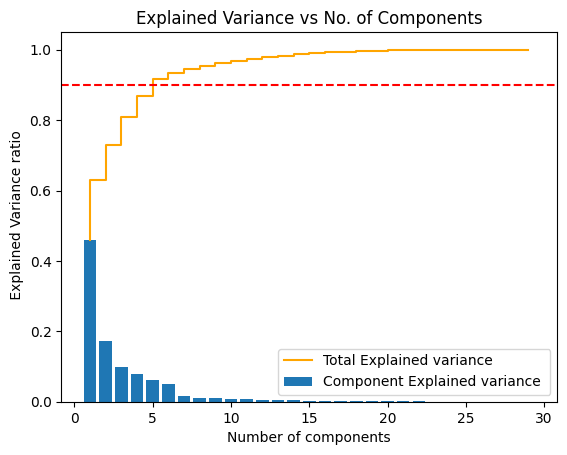

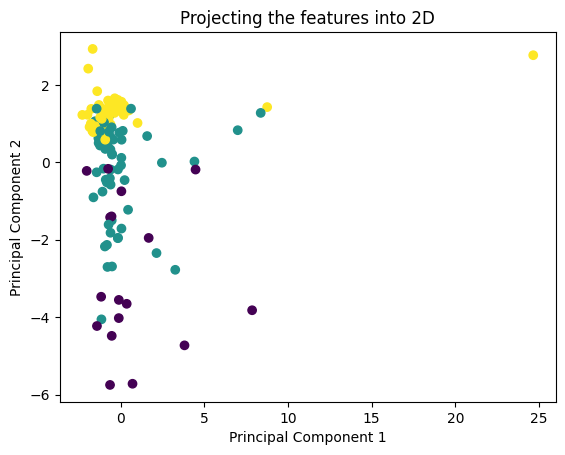

In [7]:
n = len(x_tr.columns)
LR_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",LogisticRegression())]) # currently doesnt scale binary values
PCA_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",PCA(n_components=n))]) # currently doesnt scale binary values

components =PCA_pipe.fit_transform(x_tr)
explained_var = PCA_pipe["model"].explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)
plt.bar(list(range(1,n+1)), explained_var,label = "Component Explained variance ")
plt.step(list(range(1,n+1)),cumulative_var, color = "orange",label="Total Explained variance")
plt.legend()
plt.xlabel("Number of components")
plt.title("Explained Variance vs No. of Components")
plt.ylabel(" Explained Variance ratio")
plt.axhline(y=0.9, color= "red", linestyle="--")
plt.show()
plt.scatter(components[:,0], components[:,1],c=y_tr)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Projecting the features into 2D")
plt.show()

To inspect principal component loadings,we have plotted the first 2 components (that we got after PCA on the training set), and their colour depends on their HDI/y_train
Despite the 31 feature data being reduced to 2 features, we can still see that those with similar colours are close together, especially the yellow cluster (although there are outliers)

In [8]:
principal_loading = pd.DataFrame()
for i in range(10):
 comp = np.abs(PCA_pipe["model"].components_[i])
 ind =np.argpartition(comp,-5)[-5:]
 ind = ind[np.argsort(comp[ind],descending=True)]
 principal_loading[f"PC{i+1}"] = x_tr.columns[ind]
principal_loading #Each column contains the top 5 features which contributed the most to that component

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,Inflation_consumer_prices,Access_to_electricity,GDP_Growth,Unemployment_total,Industry,Trade,Agriculture,Inflation_consumer_pricesmissing,Region_LAC,Infant_mortality
1,Trade,Individuals_using_the_Internet,Unemployment_total,GDP_Growth,Services,Industry,Access_to_electricity,Dominant_Sector_Services,Trademissing,Region_SSA
2,GDP_Growth,Infant_mortality,Trade,Access_to_electricity,Trade,Access_to_electricity,Services,Infant_mortality,Individuals_using_the_Internet,Region_EAP
3,Agriculture,Agriculture,Agriculture,Infant_mortality,Access_to_electricity,GDP_Growth,Infant_mortality,Agriculturemissing,Infant_mortality,Agriculture
4,Unemployment_total,Services,Industry,Industry,Individuals_using_the_Internet,Services,Region_EAP,Industrymissing,Region_ECA,Trademissing


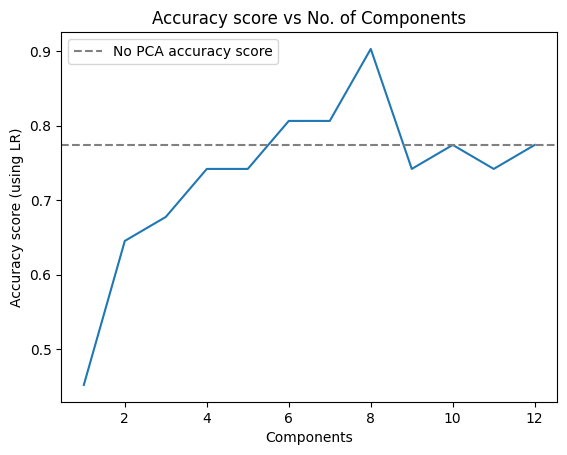

In [9]:
LR_pipe.fit(x_tr,y_tr)
y_no_pca = LR_pipe.predict(x_v)

pca_data = PCA_pipe.transform(x_v)
model = LogisticRegression() #we dont use the pipeline sinc PCA pipeline handles scaling
accuracies = []
for i in range(1,13): # after 15 its too many components
     model = LogisticRegression()
     model.fit(components[:,0:i],y_tr)
     y_pca = model.predict(pca_data[:,0:i])
     accuracies.append(accuracy_score(y_v,y_pca))


plt.plot(list(range(1,13)),accuracies)
plt.xlabel("Components")
plt.ylabel("Accuracy score (using LR)")
plt.axhline(accuracy_score(y_v,y_no_pca), color="grey",linestyle = "--",label="No PCA accuracy score")
plt.legend()
plt.title("Accuracy score vs No. of Components")
plt.show()

We compared the accuracy score of No PCA vs different number of components using PCA. To calculate the accruacy score we used LR and fit it on training set and predicted on the validation set
N=8 is the ideal value of components since it gave high accuracy at a lower value of N